# Shape-vs-Texture Bias: ResNet-50 và ViT-B/16

**Câu hỏi nghiên cứu.** Khi một ảnh đồng thời có *shape* của vật A và
*texture* của vật B, model sẽ chọn tín hiệu nào? Notebook này đi từ ảnh
cue-conflict, qua prediction ImageNet-1K và mapping chính thức 16
categories, tới ước lượng Shape Bias có khoảng tin cậy.

In [1]:
from pathlib import Path
import os, sys, json
from collections import Counter

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
# Dataset công khai; vô hiệu token cũ/hết hạn để cache công khai vẫn đọc được.
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Markdown, display
from torchvision.models import ResNet50_Weights

from src.models import load_model
from experiments.shape_texture_bias.official_mapping import (
    CATEGORIES, OFFICIAL_16_INDICES, decisions_from_probabilities,
)
from experiments.shape_texture_bias.run_shape_texture_bias import (
    DATASET_ID, category_summary, run_model, seed_everything, summarize,
)

plt.style.use('seaborn-v0_8-whitegrid')
OUT = ROOT / 'results' / 'tv4'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
seed_everything(42)
print('Thiết bị inference:', 'CUDA — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

/home/honganh/Documents/tempt/cnn-vit-interpretability/.deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thiết bị inference: CUDA — NVIDIA GeForce RTX 3060


## 1. Trực giác: một ảnh, hai lời gợi ý

*Shape* là đường bao/hình dạng của đối tượng (ví dụ thân mèo). *Texture*
là mẫu bề mặt cục bộ (ví dụ da voi). Cue-conflict images ghép hai nguồn
thông tin này bằng style transfer: ảnh không có “nhãn đúng” ImageNet
thông thường, mà có **shape cue** và **texture cue** để quan sát lựa chọn
của model.

Tổng số ảnh: 1,280; categories: 16; cue-conflict hợp lệ: 1,200.
Categories: airplane, bear, bicycle, bird, boat, bottle, car, cat, chair, clock, dog, elephant, keyboard, knife, oven, truck


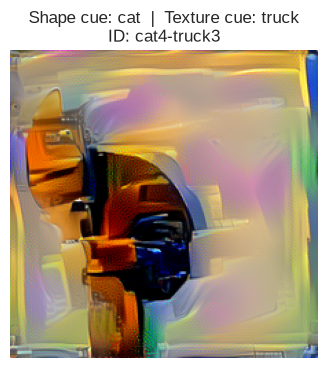

**Quan sát:** đường bao gợi `cat`, còn bề mặt/màu sắc gợi `truck`.

In [2]:
dataset = load_dataset(DATASET_ID, split='test', token=False)
records = [dataset[i] for i in range(len(dataset))]
categories = sorted({r['shape_cue'] for r in records})
valid_conflict = [r for r in records if r['shape_cue'] != r['texture_cue']]
print(f'Tổng số ảnh: {len(records):,}; categories: {len(categories)}; cue-conflict hợp lệ: {len(valid_conflict):,}.')
print('Categories:', ', '.join(categories))

# Một ảnh đầu vào thực tế để nhìn bài toán trước khi nhìn công thức.
intuition = next(r for r in records if r['shape_cue'] != r['texture_cue'])
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(intuition['image']); ax.axis('off')
ax.set_title(f"Shape cue: {intuition['shape_cue']}  |  Texture cue: {intuition['texture_cue']}\nID: {intuition['file_id']}")
plt.show()
display(Markdown('**Quan sát:** đường bao gợi `'+intuition['shape_cue']+'`, còn bề mặt/màu sắc gợi `'+intuition['texture_cue']+'`.'))

## 2. Khám phá dataset

Khác với ImageNet validation, mỗi ảnh ở đây có hai nhãn cue. Grid dưới
đây giúp kiểm tra trực tiếp dữ liệu và cho thấy các cue được kết hợp đa
dạng; biểu đồ cho biết phân bố trước khi model được chạy.

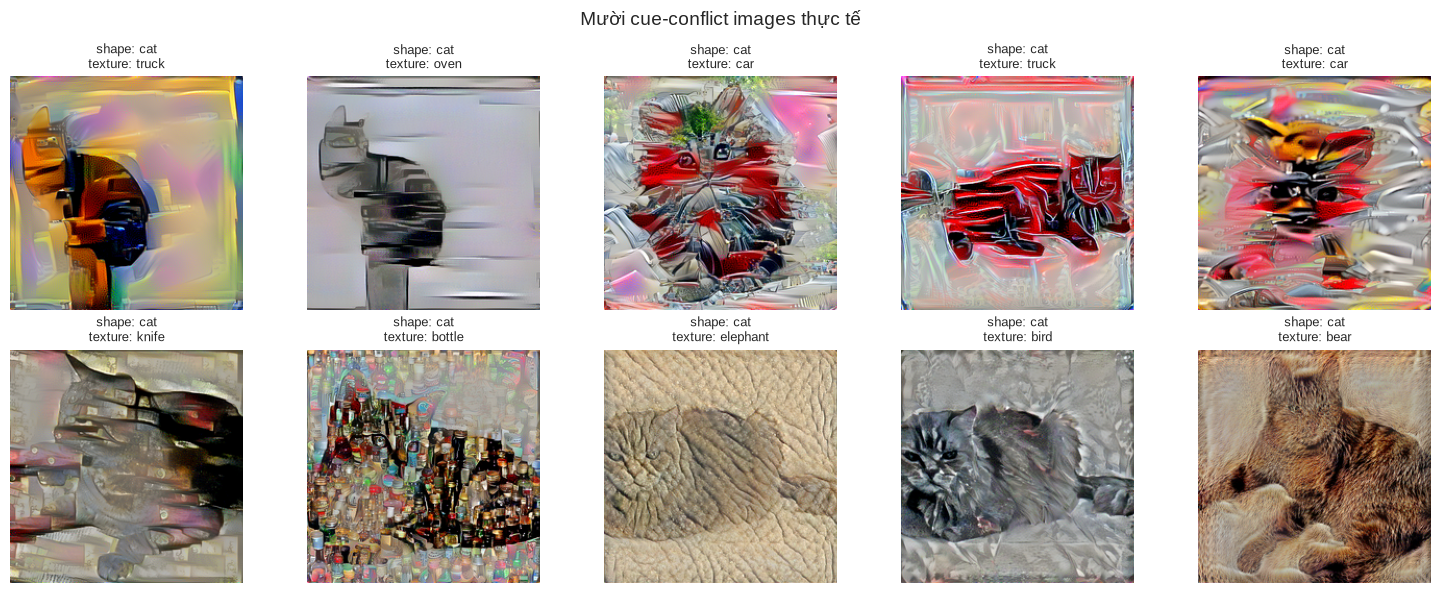

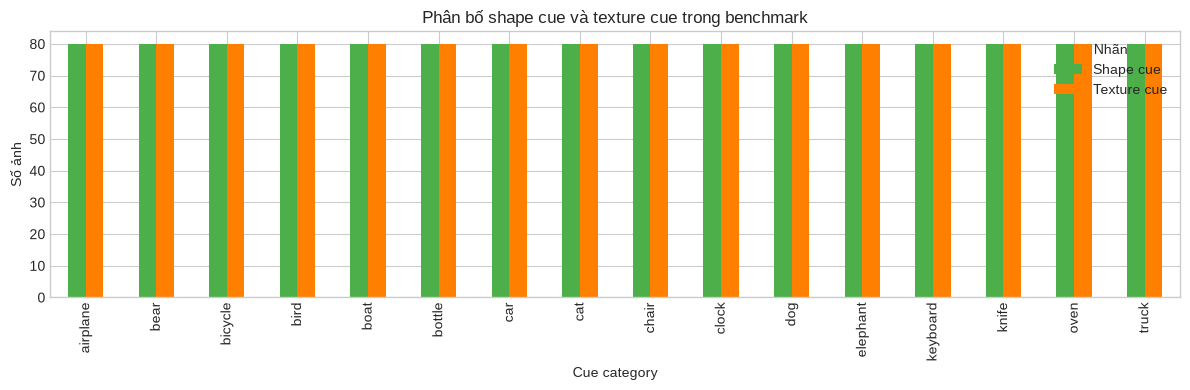

,airplane,bear,bicycle,bird,boat,bottle,car,cat,chair,clock,dog,elephant,keyboard,knife,oven,truck
Shape cue,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80
Texture cue,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, record in zip(axes.flat, valid_conflict[:10]):
    ax.imshow(record['image']); ax.axis('off')
    ax.set_title(f"shape: {record['shape_cue']}\ntexture: {record['texture_cue']}", fontsize=9)
fig.suptitle('Mười cue-conflict images thực tế', fontsize=14)
fig.tight_layout(); plt.show()

label_counts = pd.DataFrame({
    'Shape cue': Counter(r['shape_cue'] for r in records),
    'Texture cue': Counter(r['texture_cue'] for r in records),
}).fillna(0).sort_index()
ax = label_counts.plot(kind='bar', figsize=(12, 4), color=['#4daf4a', '#ff7f00'])
ax.set_title('Phân bố shape cue và texture cue trong benchmark')
ax.set_xlabel('Cue category'); ax.set_ylabel('Số ảnh'); ax.legend(title='Nhãn')
plt.tight_layout(); plt.show()
label_counts.T

## 3. Model setup

Cả hai checkpoint và phép tiền xử lý được lấy từ loader chung của nhóm.
Đây là bước quan trọng: transform riêng của mỗi checkpoint được giữ
nguyên, không tự thay resize hay normalization.

In [4]:
resnet, resnet_transform, resnet_meta = load_model('resnet50')
vit, vit_transform, vit_meta = load_model('vit_b_16')
setup = pd.DataFrame([
    {'Model': 'ResNet-50', 'Checkpoint': resnet_meta['weights'], 'Resize': resnet_meta['preprocessing']['resize_size'],
     'Crop': resnet_meta['preprocessing']['crop_size'], 'Device': resnet_meta['device'], 'Output classes': 1000},
    {'Model': 'ViT-B/16', 'Checkpoint': vit_meta['weights'], 'Resize': vit_meta['preprocessing']['resize_size'],
     'Crop': vit_meta['preprocessing']['crop_size'], 'Device': vit_meta['device'], 'Output classes': 1000},
])
setup

,Model,Checkpoint,Resize,Crop,Device,Output classes
0,ResNet-50,ResNet50_Weights.IMAGENET1K_V2,[232],[224],cuda,1000
1,ViT-B/16,ViT_B_16_Weights.IMAGENET1K_V1,[256],[224],cuda,1000


## 4. Prediction demo từng bước

Cùng một cue-conflict image đi qua preprocessing của từng model. Sau
logits ImageNet-1K, softmax probability của các class thuộc từng cue
category được **lấy trung bình** theo mapping chính thức Geirhos et al.;
category có trung bình cao nhất là decision 16-class. Vì thế không được
suy ra decision chỉ từ ImageNet top-1.

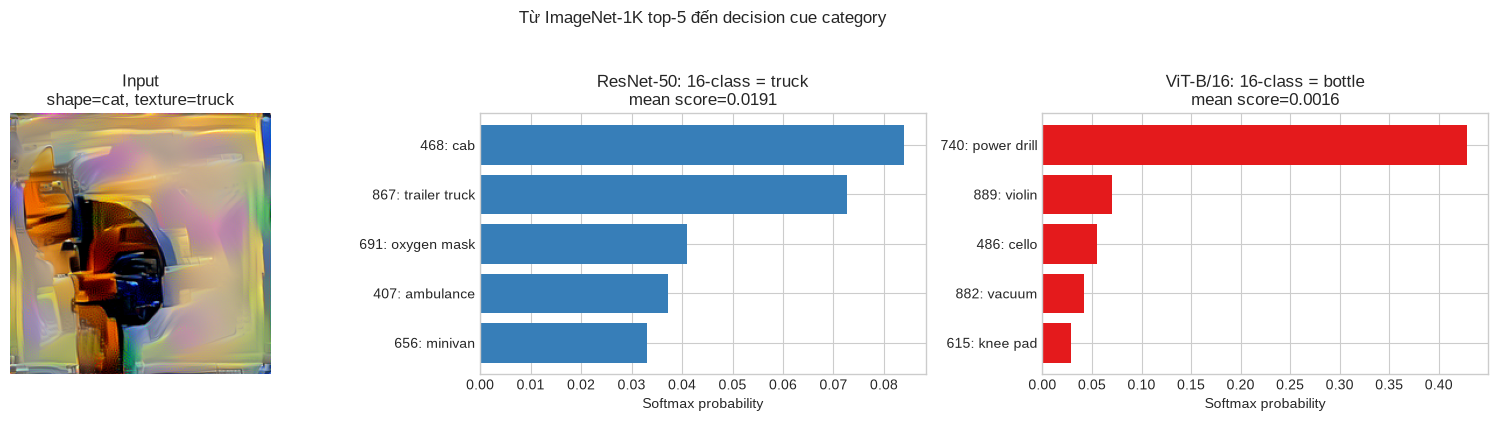

Ví dụ mapping cho decision 'truck': ImageNet indices chính thức = [555, 569, 656, 675, 717, 734, 864, 867]


,ResNet-50,ViT-B/16
airplane,0.005106,NaN
bottle,0.001398,0.001562
car,0.004722,NaN
chair,0.001879,0.000426
keyboard,NaN,0.000229
oven,NaN,0.000279
truck,0.019127,0.000350


In [5]:
imagenet_names = ResNet50_Weights.IMAGENET1K_V2.meta['categories']

def predict_one(model, transform, record):
    device = next(model.parameters()).device
    input_tensor = transform(record['image'].convert('RGB')).unsqueeze(0).to(device)
    with torch.inference_mode(), torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
        logits = model(input_tensor)
        probabilities = torch.softmax(logits.float(), dim=1).cpu().numpy()[0]
    category, category_confidence = decisions_from_probabilities(probabilities)
    top5 = probabilities.argsort()[-5:][::-1]
    scores = {name: probabilities[OFFICIAL_16_INDICES[name]].mean() for name in CATEGORIES}
    return {
        'top5': [(int(i), imagenet_names[int(i)], float(probabilities[i])) for i in top5],
        'category': category[0], 'category_confidence': float(category_confidence[0]),
        'category_scores': scores,
    }

demo = intuition
demo_predictions = {
    'ResNet-50': predict_one(resnet, resnet_transform, demo),
    'ViT-B/16': predict_one(vit, vit_transform, demo),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(demo['image']); axes[0].axis('off')
axes[0].set_title(f"Input\nshape={demo['shape_cue']}, texture={demo['texture_cue']}")
for ax, (name, prediction) in zip(axes[1:], demo_predictions.items()):
    labels = [f'{idx}: {label}' for idx, label, _ in prediction['top5']][::-1]
    values = [p for _, _, p in prediction['top5']][::-1]
    ax.barh(labels, values, color='#377eb8' if name == 'ResNet-50' else '#e41a1c')
    ax.set_xlabel('Softmax probability'); ax.set_title(f"{name}: 16-class = {prediction['category']}\nmean score={prediction['category_confidence']:.4f}")
fig.suptitle('Từ ImageNet-1K top-5 đến decision cue category', y=1.04); fig.tight_layout(); plt.show()

mapping_example = demo_predictions['ResNet-50']['category']
print(f"Ví dụ mapping cho decision '{mapping_example}': ImageNet indices chính thức = {OFFICIAL_16_INDICES[mapping_example]}")
pd.DataFrame({name: pd.Series(pred['category_scores']).sort_values(ascending=False).head(5) for name, pred in demo_predictions.items()})

## 5. Shape Bias và cache của full experiment

\[
\mathrm{Shape\ Bias}=
rac{N_{shape}}{N_{shape}+N_{texture}}.
\]

Ví dụ, 30 shape và 70 texture decisions cho Shape Bias 30%. `Neither`
không vào mẫu số vì model không chọn cue nào trong hai cue đang mâu thuẫn;
do đó notebook báo thêm **cue-decision coverage**. Cell dưới kiểm tra cache
theo số dòng, hai model và mapping. Nếu cache không hợp lệ, nó gọi utility
inference trực tiếp trên toàn benchmark (không gọi CLI).

In [6]:
prediction_path = OUT / 'shape_texture_predictions.csv'
metadata_path = OUT / 'shape_texture_metadata.json'

def cache_is_valid():
    if not prediction_path.is_file() or not metadata_path.is_file():
        return False
    cached = pd.read_csv(prediction_path)
    required = {'image_id', 'model', 'shape_cue', 'texture_cue', 'predicted_category', 'decision'}
    try:
        meta = json.loads(metadata_path.read_text(encoding='utf-8'))
    except json.JSONDecodeError:
        return False
    return (required <= set(cached.columns) and len(cached) == 2 * len(records)
            and set(cached['model']) == {'resnet50', 'vit_b_16'}
            and meta.get('mapping') == 'Official Geirhos 16-category mean-softmax mapping')

if cache_is_valid():
    predictions = pd.read_csv(prediction_path)
    cache_mode = 'Đã dùng cache prediction đã kiểm tra schema và metadata.'
else:
    del resnet, vit
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    generated = []
    for model_name in ('resnet50', 'vit_b_16'):
        rows, _ = run_model(records, model_name, batch_size=64, allow_download=True)
        generated.extend(rows)
    predictions = pd.DataFrame(generated)
    predictions.to_csv(prediction_path, index=False)
    cache_mode = 'Cache không hợp lệ/không có: đã chạy full inference và tạo prediction cache mới.'
print(cache_mode)
print('Prediction rows:', len(predictions), '| unique (image, model):', predictions[['image_id', 'model']].drop_duplicates().shape[0])

Đã dùng cache prediction đã kiểm tra schema và metadata.
Prediction rows: 2560 | unique (image, model): 2560


In [7]:
summary_rows = []
for model_name in ('resnet50', 'vit_b_16'):
    row = summarize(predictions[predictions.model == model_name].to_dict('records'), seed=42)
    summary_rows.append({'model': model_name, **row})
summary = pd.DataFrame(summary_rows)
summary_display = summary.copy()
for column in ['cue_decision_coverage', 'shape_bias', 'shape_bias_ci95_low', 'shape_bias_ci95_high']:
    summary_display[column] = (100 * summary_display[column]).map(lambda x: f'{x:.2f}%')
summary_display

,model,num_all_images,num_valid_cue_conflict,shape_decisions,texture_decisions,neither_decisions,cue_decision_coverage,shape_bias,shape_bias_ci95_low,shape_bias_ci95_high
0,resnet50,1280,1200,181,671,348,71.00%,21.24%,18.52%,24.09%
1,vit_b_16,1280,1200,326,493,381,68.25%,39.80%,36.45%,43.12%


## 6. Bằng chứng định lượng

Ba biểu đồ sau được dựng trực tiếp từ records cache/inference của cell
trước. Chúng đồng thời được lưu vào `results/tv4/figures/` để dùng trong
report/slides.

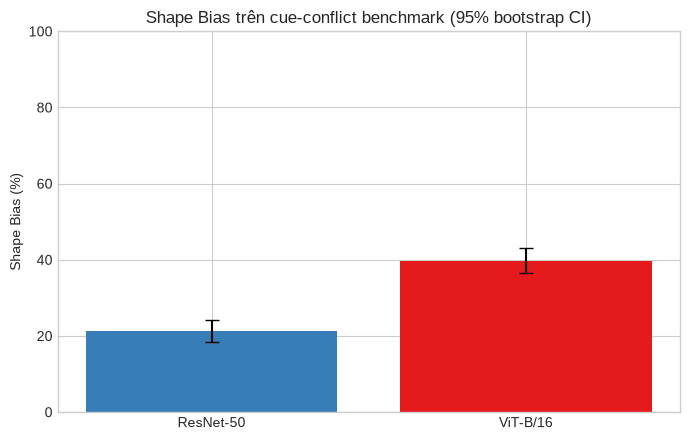

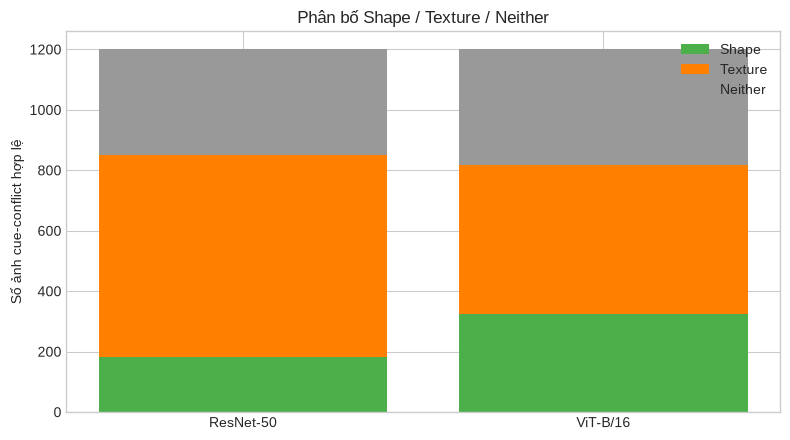

In [8]:
labels = {'resnet50': 'ResNet-50', 'vit_b_16': 'ViT-B/16'}
colors = {'resnet50': '#377eb8', 'vit_b_16': '#e41a1c'}
fig, ax = plt.subplots(figsize=(7, 4.5))
values = 100 * summary.set_index('model').loc[list(labels), 'shape_bias']
low = 100 * summary.set_index('model').loc[list(labels), 'shape_bias_ci95_low']
high = 100 * summary.set_index('model').loc[list(labels), 'shape_bias_ci95_high']
ax.bar([labels[m] for m in labels], values, yerr=np.vstack([values-low, high-values]), capsize=5, color=[colors[m] for m in labels])
ax.set_ylabel('Shape Bias (%)'); ax.set_ylim(0, 100); ax.set_title('Shape Bias trên cue-conflict benchmark (95% bootstrap CI)')
fig.tight_layout(); fig.savefig(FIGURES / 'shape_bias_comparison.png', dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5)); bottom = np.zeros(2)
for decision, color in [('shape', '#4daf4a'), ('texture', '#ff7f00'), ('neither', '#999999')]:
    values = summary.set_index('model').loc[list(labels), f'{decision}_decisions'].to_numpy()
    ax.bar([labels[m] for m in labels], values, bottom=bottom, label=decision.title(), color=color); bottom += values
ax.set_ylabel('Số ảnh cue-conflict hợp lệ'); ax.set_title('Phân bố Shape / Texture / Neither'); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / 'decision_stacked_bar.png', dpi=300); plt.show()

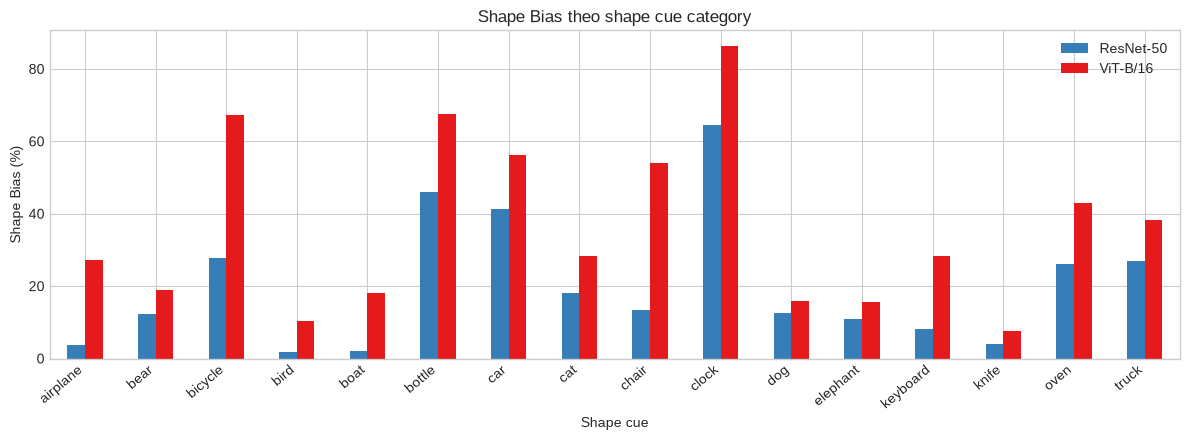

**Diễn giải:** ViT-B/16 có Shape Bias tổng cao hơn; biểu đồ category-level cho thấy mức chênh không đồng nhất giữa các category.

In [9]:
category_tables = []
for model_name in ('resnet50', 'vit_b_16'):
    table = pd.DataFrame(category_summary(predictions[predictions.model == model_name].to_dict('records')))
    table['model'] = model_name; category_tables.append(table)
category_metrics = pd.concat(category_tables, ignore_index=True)
pivot = category_metrics.pivot(index='shape_cue', columns='model', values='shape_bias').sort_index()
ax = (100 * pivot).plot(kind='bar', figsize=(12, 4.5), color=[colors['resnet50'], colors['vit_b_16']])
ax.set_title('Shape Bias theo shape cue category'); ax.set_xlabel('Shape cue'); ax.set_ylabel('Shape Bias (%)')
ax.legend(['ResNet-50', 'ViT-B/16']); plt.xticks(rotation=40, ha='right'); plt.tight_layout()
plt.savefig(FIGURES / 'category_shape_bias.png', dpi=300); plt.show()
display(Markdown('**Diễn giải:** ViT-B/16 có Shape Bias tổng cao hơn; biểu đồ category-level cho thấy mức chênh không đồng nhất giữa các category.'))

## 7. Qualitative case studies được chọn bằng prediction records

Không chọn ảnh bằng tay để minh họa một kết luận có sẵn. Code dưới lọc
giao của hai model theo decision thực tế, lấy hai image IDs đầu tiên của
mỗi nhóm (thứ tự dataset), rồi hiển thị ảnh cùng label, prediction
category và confidence mapping.

ResNet texture — ViT shape: 117 ảnh; hiển thị 2.
ResNet shape — ViT texture: 15 ảnh; hiển thị 2.
Cả hai shape: 150 ảnh; hiển thị 2.
Cả hai texture: 391 ảnh; hiển thị 2.
Có Neither: 527 ảnh; hiển thị 2.


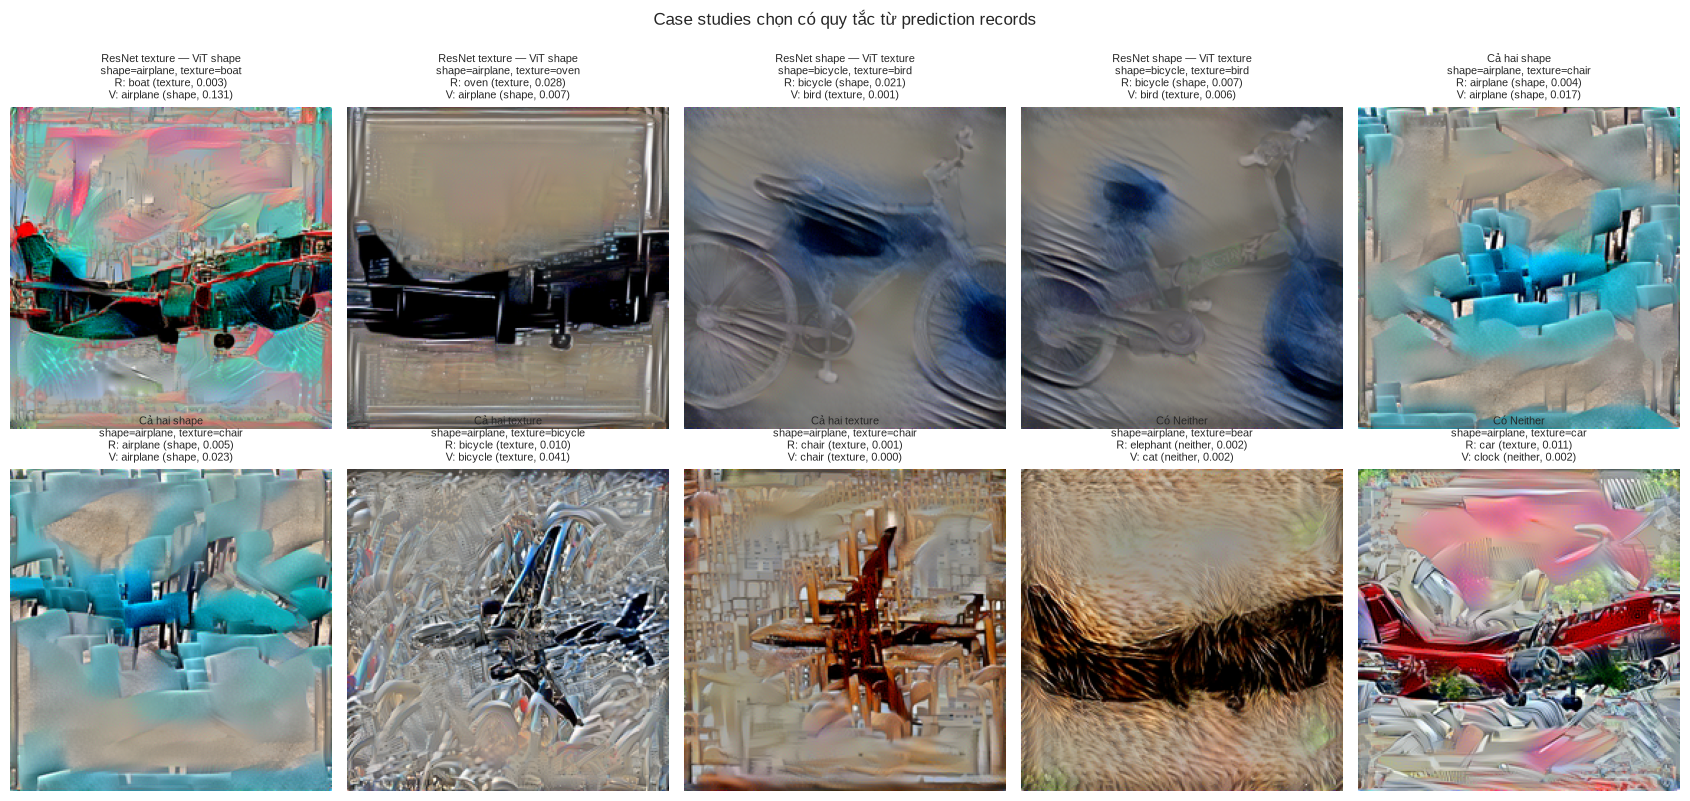

In [10]:
record_by_id = {r['file_id']: r for r in records}
wide = predictions.pivot(index='image_id', columns='model', values=['decision', 'predicted_category', 'category_confidence', 'shape_cue', 'texture_cue'])
groups = [
    ('ResNet texture — ViT shape', 'texture', 'shape'),
    ('ResNet shape — ViT texture', 'shape', 'texture'),
    ('Cả hai shape', 'shape', 'shape'),
    ('Cả hai texture', 'texture', 'texture'),
    ('Có Neither', None, None),
]
selected = []
for title, r_decision, v_decision in groups:
    if r_decision is None:
        mask = (wide['decision']['resnet50'] == 'neither') | (wide['decision']['vit_b_16'] == 'neither')
    else:
        mask = (wide['decision']['resnet50'] == r_decision) & (wide['decision']['vit_b_16'] == v_decision)
    ids = list(wide[mask].index[:2])
    selected.extend((title, image_id) for image_id in ids)
    print(f'{title}: {len(wide[mask])} ảnh; hiển thị {len(ids)}.')

if selected:
    fig, axes = plt.subplots(2, int(np.ceil(len(selected)/2)), figsize=(17, 8))
    for ax, (title, image_id) in zip(axes.flat, selected):
        row = wide.loc[image_id]; record = record_by_id[image_id]
        ax.imshow(record['image']); ax.axis('off')
        ax.set_title(
            f"{title}\nshape={record['shape_cue']}, texture={record['texture_cue']}\n"
            f"R: {row[('predicted_category','resnet50')]} ({row[('decision','resnet50')]}, {row[('category_confidence','resnet50')]:.3f})\n"
            f"V: {row[('predicted_category','vit_b_16')]} ({row[('decision','vit_b_16')]}, {row[('category_confidence','vit_b_16')]:.3f})",
            fontsize=8)
    for ax in axes.flat[len(selected):]: ax.axis('off')
    fig.suptitle('Case studies chọn có quy tắc từ prediction records', y=1.01); fig.tight_layout(); plt.show()

## 8. Discussion, limitations và references

**Quan sát.** Trên 1.200 cue-conflict images hợp lệ, ViT-B/16 có Shape
Bias cao hơn ResNet-50 **18,56 percentage points** (39,80% so với
21,24%). Khoảng tin cậy bootstrap của hai estimate không chồng nhau trong
run này. Các case studies cho thấy chênh lệch tổng hợp xuất hiện ở nhiều
ảnh, nhưng không đồng nghĩa ViT luôn chọn shape hay CNN luôn chọn texture.

**Giới hạn.** Đây là một cặp checkpoint ImageNet, 16 entry-level
categories và stimulus style-transfer; Neither vẫn chiếm tỷ lệ đáng kể.
Bootstrap mô tả bất định sampling của benchmark, không suy rộng thành kết
luận phổ quát về mọi kiến trúc.

**References.** Geirhos et al. (2019), *ImageNet-trained CNNs are biased
towards texture*, ICLR: https://openreview.net/forum?id=Bygh9j09KX. Official
mapping: https://github.com/rgeirhos/texture-vs-shape. Dataset:
https://huggingface.co/datasets/rgeirhos/texture-shape-cue-conflict.